# Multi-Asset Allocation: Markowitz, Risk Parity and Black-Litterman

**Goal.** Allocate a diversified fund across eight asset classes, and understand why
practitioners rarely use textbook Markowitz optimisation as it is:

1. **Markowitz is fragile**: small errors in expected returns produce extreme, unstable weights.
2. **Risk parity** ignores return forecasts and balances the *risk* each asset contributes.
3. **Black-Litterman** starts from the returns implied by the market and blends in the
   manager's views, with a confidence for each.

Volatilities and correlations are long-run estimates typical of each asset class.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("allocation.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/17-risk-parity-black-litterman")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from allocation import (ASSETS, VOLS, CORR, MARKET_WEIGHTS, covariance, portfolio_stats, risk_contributions, min_variance,
                        max_sharpe, efficient_frontier, risk_budget_portfolio, inverse_volatility, implied_returns,
                        black_litterman, mean_variance_weights, unconstrained_weights)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
PALETTE = [NAVY, "#4a6d8c", TEAL, "#7fb3b3", GOLD, BORDEAUX, "#c07a7a", GREY]
cov = covariance()
pi = implied_returns(cov, MARKET_WEIGHTS, risk_aversion=2.5, rf=0.02)
pd.DataFrame({"Volatility": VOLS, "Market weight": MARKET_WEIGHTS, "Implied return (Pi)": pi}, index=ASSETS).style.format("{:.1%}")

,Volatility,Market weight,Implied return (Pi)
Global equities,15.0%,38.0%,5.0%
EM equities,21.0%,7.0%,5.7%
Govt bonds,5.0%,25.0%,2.2%
IG credit,6.5%,14.0%,2.7%
High yield,10.0%,4.0%,3.6%
Listed real estate,18.0%,4.0%,5.1%
Commodities,20.0%,4.0%,3.9%
Gold,16.0%,4.0%,2.8%


**Implied returns.** Instead of forecasting returns, Black-Litterman asks: *which expected
returns would make today's market portfolio optimal?* Reverse optimisation gives
$\Pi = r_f + \delta\,\Sigma\,w_{mkt}$ with a risk aversion $\delta = 2.5$. These returns are
consistent with the risks and with the prices investors are actually paying.

## 1. Why plain Markowitz fails

Suppose the true expected returns are $\Pi$, but we estimate them from 10 years of monthly
data, as a naive analyst would. Each resampled history gives a different max-Sharpe portfolio.

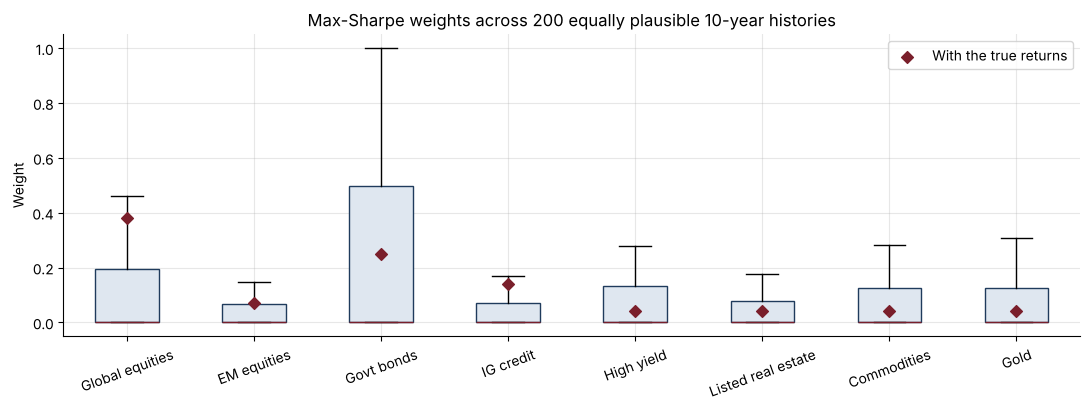

Average number of assets above 1% weight: 2.8 of 8
Average weight change between two histories: 77% of the portfolio


In [2]:
rng = np.random.default_rng(0)
L = np.linalg.cholesky(cov / 12)
samples = []
for _ in range(200):
    hist = pi / 12 + rng.standard_normal((120, 8)) @ L.T
    samples.append(max_sharpe(hist.mean(axis=0) * 12, cov))
samples = np.array(samples)
fig, ax = plt.subplots(figsize=(11, 4.2))
bp = ax.boxplot([samples[:, i] for i in range(8)], tick_labels=ASSETS, patch_artist=True, showfliers=False,
                boxprops=dict(facecolor="#dfe7f0", color=NAVY), medianprops=dict(color=BORDEAUX))
ax.scatter(range(1, 9), max_sharpe(pi, cov), color=BORDEAUX, marker="D", zorder=4, label="With the true returns")
ax.set_ylabel("Weight"); ax.set_title("Max-Sharpe weights across 200 equally plausible 10-year histories")
plt.xticks(rotation=20); ax.legend(); plt.tight_layout(); plt.savefig("images/markowitz_instability.png", dpi=150); plt.show()
print(f"Average number of assets above 1% weight: {(samples > 0.01).sum(axis=1).mean():.1f} of 8")
print(f"Average weight change between two histories: {np.abs(samples[1:] - samples[:-1]).sum(axis=1).mean() / 2:.0%} of the portfolio")

Ten years of data cannot pin down expected returns: the standard error of a 15%-vol asset's
mean return over 10 years is about 4.7% a year. The optimiser treats this noise as signal and
concentrates the portfolio in whatever looked best. This is "error maximisation".

## 2. Risk parity

Risk parity needs only the covariance matrix. Each asset's **risk contribution**
$RC_i = w_i\,(\Sigma w)_i/\sigma_p$ (the contributions add up to the portfolio volatility) is
set equal across assets. We solve Spinu's convex formulation, which always converges.

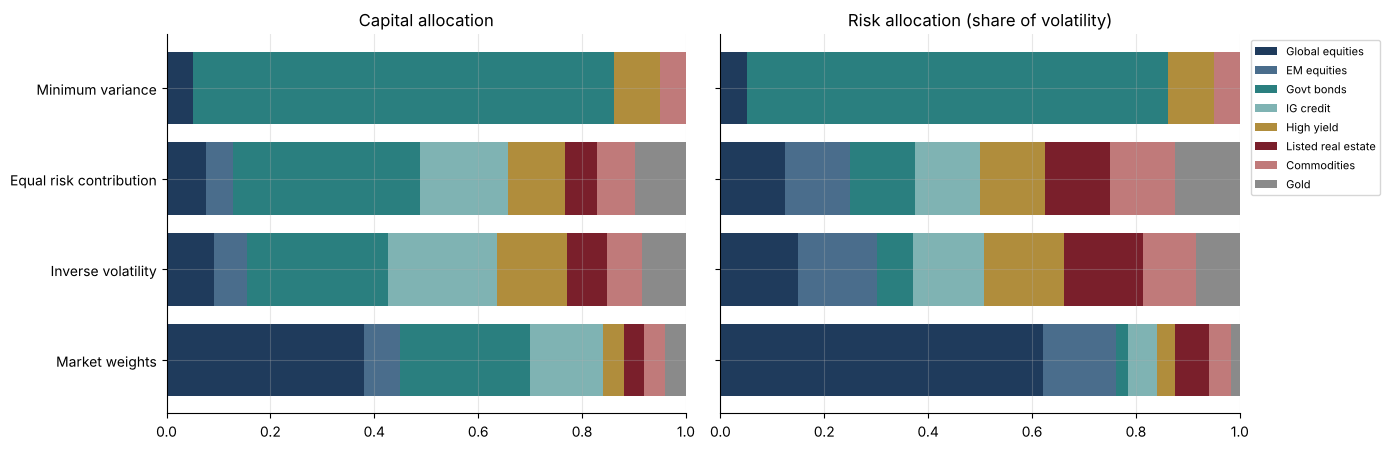

,return,vol,sharpe
Market weights,3.85%,8.60%,0.21
Inverse volatility,3.36%,6.81%,0.20
Equal risk contribution,3.19%,6.22%,0.19
Minimum variance,2.52%,4.40%,0.12


In [3]:
portfolios = {"Market weights": MARKET_WEIGHTS, "Inverse volatility": inverse_volatility(cov),
              "Equal risk contribution": risk_budget_portfolio(cov), "Minimum variance": min_variance(cov)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, kind in zip(axes, ["weights", "risk"]):
    left = np.zeros(len(portfolios))
    for i, asset in enumerate(ASSETS):
        vals = np.array([w[i] if kind == "weights" else risk_contributions(w, cov)[i] / np.sqrt(w @ cov @ w)
                         for w in portfolios.values()])
        ax.barh(list(portfolios), vals, left=left, color=PALETTE[i], label=asset)
        left += vals
    ax.set_title("Capital allocation" if kind == "weights" else "Risk allocation (share of volatility)")
    ax.set_xlim(0, 1)
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("images/risk_parity.png", dpi=150); plt.show()
pd.DataFrame({k: portfolio_stats(w, pi, cov) for k, w in portfolios.items()}).T.style.format({"return": "{:.2%}", "vol": "{:.2%}", "sharpe": "{:.2f}"})

**Reading the chart.** The market portfolio is a 38% equity allocation in capital terms, but
equities and equity-like assets account for most of its risk. Risk parity gives each asset the
same share of risk, which means much more in government bonds and credit. To reach equity-like
returns, risk-parity funds apply leverage to this low-volatility portfolio.

## 3. Black-Litterman: adding the manager's views

Three views, each with its own confidence:

| View | Type | Confidence |
|---|---|---|
| EM equities beat global equities by 3% a year | relative | 60% |
| Gold returns 7% a year | absolute | 40% |
| High yield beats IG credit by 2% a year | relative | 30% |

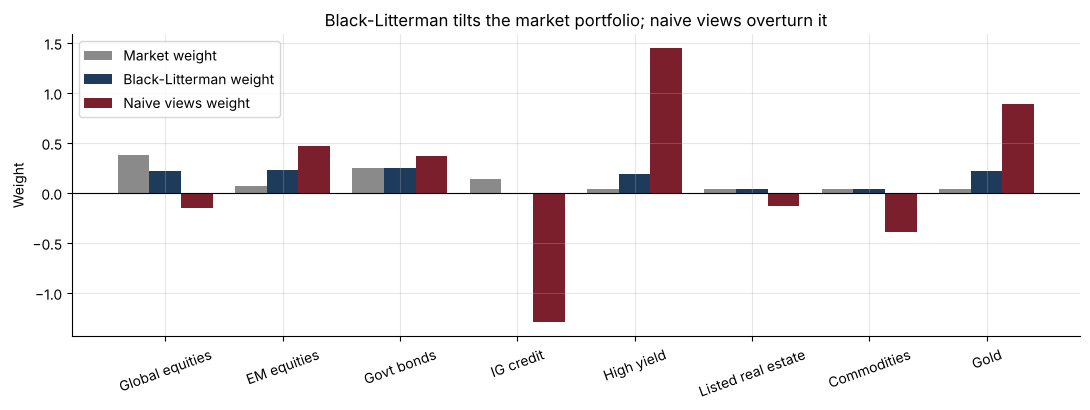

Sum of weights: market 100%, Black-Litterman 118%, naive 120%


,Equilibrium return,Black-Litterman return,Market weight,Black-Litterman weight,Naive views weight
Global equities,5.0%,5.4%,38.0%,22.0%,-15.3%
EM equities,5.7%,7.1%,7.0%,23.0%,47.4%
Govt bonds,2.2%,2.2%,25.0%,25.0%,36.7%
IG credit,2.7%,2.9%,14.0%,-1.1%,-129.5%
High yield,3.6%,4.0%,4.0%,19.1%,144.7%
Listed real estate,5.1%,5.6%,4.0%,4.0%,-12.9%
Commodities,3.9%,4.9%,4.0%,4.0%,-39.5%
Gold,2.8%,4.1%,4.0%,22.3%,88.9%


In [4]:
P = np.zeros((3, 8))
P[0, 1], P[0, 0] = 1, -1
P[1, 7] = 1
P[2, 4], P[2, 3] = 1, -1
Q = np.array([0.03, 0.07, 0.02])
mu_bl, cov_bl = black_litterman(cov, pi, P, Q, tau=0.05, confidences=[0.6, 0.4, 0.3])
w_bl = unconstrained_weights(mu_bl, cov, risk_aversion=2.5)

naive_mu = pi.copy()                                   # "plug the views in directly" approach
naive_mu[1] = pi[0] + 0.03; naive_mu[7] = 0.07; naive_mu[4] = pi[3] + 0.02
w_naive = unconstrained_weights(naive_mu, cov, risk_aversion=2.5)

comp = pd.DataFrame({"Equilibrium return": pi, "Black-Litterman return": mu_bl, "Market weight": MARKET_WEIGHTS,
                     "Black-Litterman weight": w_bl, "Naive views weight": w_naive}, index=ASSETS)
fig, ax = plt.subplots(figsize=(11, 4.2))
xs = np.arange(8)
for k, (col, c) in enumerate([("Market weight", GREY), ("Black-Litterman weight", NAVY), ("Naive views weight", BORDEAUX)]):
    ax.bar(xs + (k - 1) * 0.27, comp[col], width=0.27, color=c, label=col)
ax.set_xticks(xs, ASSETS, rotation=20); ax.set_ylabel("Weight"); ax.legend()
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Black-Litterman tilts the market portfolio; naive views overturn it")
plt.tight_layout(); plt.savefig("images/black_litterman.png", dpi=150); plt.show()
print(f"Sum of weights: market {MARKET_WEIGHTS.sum():.0%}, Black-Litterman {w_bl.sum():.0%}, naive {w_naive.sum():.0%}")
comp.style.format("{:.1%}")

**Reading the result.** Weights are the closed-form optimum $w = (\delta\Sigma)^{-1}(\mu - r_f)$,
as in the original paper. Black-Litterman changes **only the assets involved in a view**:
government bonds, real estate and commodities keep exactly their market weights, while
EM equities, gold and high yield are tilted up (and global equities and IG credit down) in
proportion to the confidence in each view. Plugging the same views directly into Markowitz
produces huge long-short bets: the same error maximisation as in section 1.

## 4. The efficient frontier

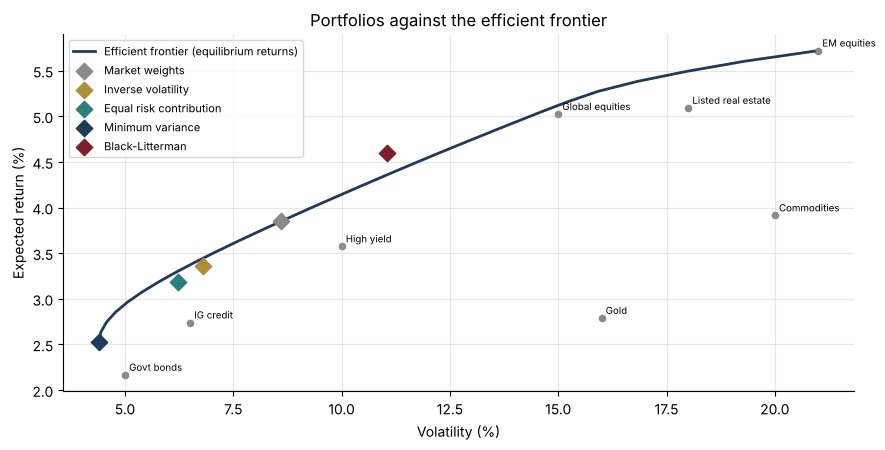

In [5]:
frontier = efficient_frontier(pi, cov, 30)
plt.figure(figsize=(9, 4.6))
plt.plot([f[0] * 100 for f in frontier], [f[1] * 100 for f in frontier], color=NAVY, lw=2, label="Efficient frontier (equilibrium returns)")
plt.scatter(VOLS * 100, pi * 100, color=GREY, s=20)
for a, v, m in zip(ASSETS, VOLS, pi):
    plt.annotate(a, (v * 100, m * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
for (name, w), c in zip({**portfolios, "Black-Litterman": w_bl}.items(), [GREY, GOLD, TEAL, NAVY, BORDEAUX]):
    st = portfolio_stats(w, pi, cov)
    plt.scatter(st["vol"] * 100, st["return"] * 100, color=c, s=70, marker="D", label=name, zorder=4)
plt.xlabel("Volatility (%)"); plt.ylabel("Expected return (%)"); plt.legend(fontsize=8)
plt.title("Portfolios against the efficient frontier")
plt.tight_layout(); plt.savefig("images/frontier.png", dpi=150); plt.show()

## Conclusions
- Markowitz with estimated returns is unstable: equally plausible histories give completely
  different portfolios.
- Risk parity is robust (covariances are much easier to estimate than means) and balances
  the risk the market portfolio concentrates in equities.
- Black-Litterman makes views usable: it starts from equilibrium and tilts in proportion to
  conviction. The tests check that reverse optimisation returns the market weights exactly.
- **Next steps:** shrinkage covariance estimators (Ledoit-Wolf), hierarchical risk parity,
  transaction-cost-aware rebalancing, and a backtest of each strategy (project 19).